# Pertemuan 7 — Praktikum 2: Regresi Non-Linier dengan SVR

Support Vector Regression (SVR) adalah varian Support Vector Machine yang dipakai untuk memprediksi nilai kontinu. Berbeda dengan SVM yang memisahkan data menjadi dua zona, SVR berusaha memasukkan seluruh data ke dalam satu pita (tube) dengan lebar $\varepsilon$ sekecil mungkin. Karena memakai fungsi kernel, SVR mampu memodelkan hubungan non-linier antara variabel bebas dan variabel target.

Praktikum ini menerapkan SVR berkernel Radial Basis Function (RBF) pada data tingkat posisi dan gaji. Seluruh fitur dan target diskalakan terlebih dahulu karena SVR sangat sensitif terhadap perbedaan skala data.

Sumber: [Praktikum 2](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-regresi/praktikum2).

## 1. Mengimpor library

Sel berikut memuat pustaka NumPy, Matplotlib, dan Pandas yang dipakai selama praktikum.

In [1]:
%matplotlib inline

# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 2. Mengimpor dataset

Berkas `Posisi_gaji.csv` dibaca dengan `pd.read_csv`. Kolom kedua berisi tingkat posisi (Level) yang dipakai sebagai variabel bebas, sedangkan kolom ketiga berisi gaji (Gaji) sebagai variabel target. Kolom pertama hanya memuat nama posisi dan tidak dipakai dalam model.

In [2]:
# Mengimpor dataset
dataset = pd.read_csv('Posisi_gaji.csv')

X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

display(dataset.head(10))
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


Ukuran X: (10, 1)
Ukuran y: (10,)


## 3. Feature scaling

Nilai tingkat posisi berkisar antara 1 sampai 10, sedangkan gaji mencapai jutaan. Perbedaan skala yang besar membuat SVR sulit bekerja dengan baik, sehingga fitur dan target diskalakan dengan `StandardScaler` agar memiliki rata-rata nol dan simpangan baku satu.

In [3]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

sc_X = StandardScaler()
sc_y = StandardScaler()

X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1)).ravel()

## 4. Fitting SVR ke dataset

Model SVR dibuat dengan kernel RBF, yaitu kernel yang memetakan data ke ruang berdimensi lebih tinggi sehingga hubungan non-linier dapat ditangani. Model kemudian dilatih pada data yang telah diskalakan.

In [4]:
# Fitting SVR ke dataset
from sklearn.svm import SVR

regressor = SVR(kernel='rbf')
regressor.fit(X, y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


## 5. Visualisasi hasil SVR

Hasil prediksi digambarkan pada grid nilai tingkat posisi yang halus. Titik merah merupakan data asli, sedangkan garis biru merupakan kurva hasil prediksi SVR. Kurva tersebut memperlihatkan hubungan non-linier antara tingkat posisi dan gaji.

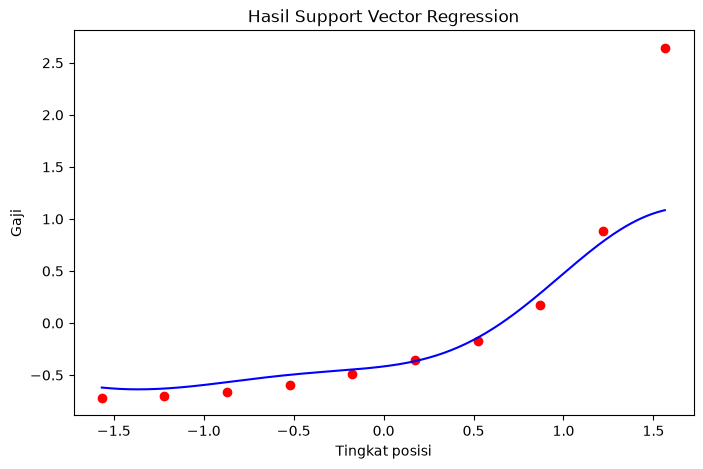

In [5]:
# Visualisasi hasil SVR
X_grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Hasil Support Vector Regression')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

## 6. Prediksi hasil

Model dipakai untuk memprediksi gaji pada tingkat posisi 6,5. Nilai tersebut terlebih dahulu diskalakan dengan `sc_X`, diprediksi oleh model, lalu dikembalikan ke skala asli dengan `sc_y.inverse_transform`.

In [6]:
# Prediksi hasil
tingkat_posisi_prediksi = np.array([[6.5]])

# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)

# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)

# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


## 7. Evaluasi model SVR

Kinerja model diukur dengan Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), dan R-squared. Perhitungan memakai data yang telah diskalakan agar sebanding dengan skala keluaran model.

In [7]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.2229927409573441
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


## Kesimpulan

SVR berkernel RBF dapat memodelkan hubungan non-linier antara tingkat posisi dan gaji dengan baik. Model memprediksi gaji untuk tingkat posisi 6,5 sebesar 170.370,02 dolar. Nilai MAE 0,2230 dan RMSE 0,4984 pada data terskalakan menunjukkan kesalahan prediksi yang relatif kecil, sedangkan R-squared sebesar 0,7516 berarti sekitar 75% keragaman data berhasil dijelaskan model. Pensakalaan fitur dan target menjadi langkah penting karena SVR sangat peka terhadap skala data.